# Email spam detection

In [1]:
# Project 5: Spam Detection Using Naive Bayes + TF-IDF

# step 1: importing the libraries

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# step 2: reading the dataset 
df = pd.read_csv("spam_dataset.csv")


In [3]:
df.head()

,label,message
0,ham,Hey! Are we still meeting for lunch today?
1,ham,I'll call you later.
2,spam,Congratulations! You've won a $500 gift card. ...
3,spam,URGENT! Your account has been suspended. Click...
4,ham,Don't forget to bring the documents tomorrow.


In [4]:
# step 3: Encode labels

df['label_encoded'] = df['label'].map({'ham': 0, 'spam': 1})
print(df.head)

# Why? ML algorithms need numbers, not words


<bound method NDFrame.head of    label                                            message  label_encoded
0    ham         Hey! Are we still meeting for lunch today?              0
1    ham                               I'll call you later.              0
2   spam  Congratulations! You've won a $500 gift card. ...              1
3   spam  URGENT! Your account has been suspended. Click...              1
4    ham      Don't forget to bring the documents tomorrow.              0
5    ham             Happy birthday! Wish you all the best.              0
6   spam  Win a FREE vacation to Bahamas! Text WIN to 90...              1
7   spam  You have been selected for a free prize. Call ...              1
8    ham                   Please find the attached report.              0
9    ham         Can you send me the photos from yesterday?              0
10  spam          Limited time offer!!! Buy 1 Get 1 FREE!!!              1
11  spam                   Claim your lottery winnings now!           

In [5]:
# step 4: Train / Test Split

X_train, X_test, y_train, y_test = train_test_split(
    df['message'],
    df['label_encoded'],
    test_size=0.2,
    random_state=42
)

# train → learning

# test → evaluation

# 20% test gives good balance

In [6]:
#step 5: TF-IDF Vectorization

tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# TF-IDF converts text to numbers by weighting important words like:
# "FREE", "OFFER", "WIN", "PRIZE"

In [7]:
# step 6: Train Naive Bayes Model

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)


# Why Naive Bayes?
# Very fast, Works great for text, low memory usuage


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [8]:
# step 7: Make Predictions

y_pred = model.predict(X_test_tfidf)

In [9]:
# step 8: Evaluate Model

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['ham', 'spam']))
print("\n Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


# Accuracy: overall correctness
# Precision: quality of spam predictions
# Recall: how many spam messages were caught
# Confusion Matrix: breakdown of TP, TN, FP, FN


Accuracy: 0.875

Classification Report:
               precision    recall  f1-score   support

         ham       1.00      0.83      0.91         6
        spam       0.67      1.00      0.80         2

    accuracy                           0.88         8
   macro avg       0.83      0.92      0.85         8
weighted avg       0.92      0.88      0.88         8


 Confusion Matrix:
 [[5 1]
 [0 2]]


In [10]:
# Step 9: Try Custom User Input

sample_msgs=[
    "Congratulations! You have won a FREE prize. Call now!",
    "Hey bro, are we still meeting tomorrow?"
]

sample_tfidf = tfidf.transform(sample_msgs)
print(model.predict(sample_tfidf))

[1 0]


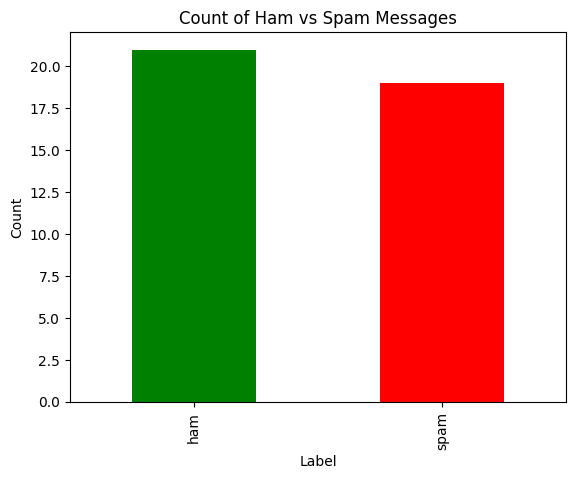

In [11]:
#last Step: Bar Chart of Spam vs Ham Distribution

import matplotlib.pyplot as plt

df['label'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Count of Ham vs Spam Messages')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()
